# palette

> Generating the design system's colour tokens

## Design Rationale

Most design systems name their colours by role — `primary`, `secondary`, `surface`, `outline`, `muted`, `destructive` — and hand-pick each one. Many roles need more than one shade (a danger button, a danger alert, danger text), so each becomes a small bundle of swatches. A new context (warning, dark mode) multiplies the bundles. The result is a growing grid of named swatches, each verified for its own situation but with no guarantee that the grid is complete, consistent, or extensible without further hand-picking.

What we argue for instead is a generator: pick a hue, and get a complete family, with every colour tailored for a named job, and every hue yielding a family of the same quality. The structure that makes this possible is a **ladder of prominence steps**, an ordinal ramp where a component reads position as meaning: negative steps are less prominent, and positive steps are more prominent. For example, step 0 is the solid, +1 is the hover, −2 is the background. By attaching contrast or separation targets to rungs of the ladder, colours can be numerically derived instead of chosen by eye.

A UI needs two such ladders: the **vivid ladder** carries the accent family (buttons, links, alert fills, focus rings); the **neutral ladder** carries the workhorse colours (page, surface, border, and text). The neutral ladder should take the same hue as the vivid one, at near-zero chroma, so a context tints everything inside it, not just the accents.

Deriving each rung from stated requirements means a changed assumption (a contrast target, more/fewer rungs, more/less tint) regenerates a sensible palette. Here we state the desired properties of our palette and generator:

### Properties of the palette

- **P1. Perceptual uniformity across hue.** Steps at the same prominence should read as equally bright regardless of hue. A yellow solid and a blue solid at the same step must carry the same visual weight (we don't want some palettes to result in glowing buttons and others muted ones).
- **P2. Step distinctness.** Adjacent steps on each ladder must be perceptually separable at every hue, so that a component reading position as meaning can rely on the viewer seeing the difference.
- **P3. Guaranteed contrast at every hue.** Contrast targets must hold for *all* hues. [WCAG 2 ratios](https://www.w3.org/WAI/WCAG21/Understanding/contrast-minimum.html) should be used to structure the steps of each ladder.
- **P4. Hue interchangeability.** Any hue should produce an equally usable family. No hue should require a special case or produce a broken result (neon, illegible).
- **P5. Dual-theme support.** Both light and dark themes should be supported and coherent; that is, recognisably the same family and each fully meeting its uniformity and contrast requirements.
- **P6. Context extensibility.** A named context (danger, warning, success, etc.) should require nothing beyond a hue value.

### Properties of the generator

- **G1. Browser-native derivation.** The browser should compute colours from the hue at runtime, without pre-computed colour tables or JavaScript.
- **G2. Gamut-aware.** Chroma at each step must respect the actual sRGB gamut boundary at that lightness and hue, so the browser never silently clamps an out-of-gamut colour to something unverified.
- **G3. Contrast-derived anchors.** Ladder steps that carry WCAG obligations (e.g. text on primary button) should be derived from the contrast targets, not picked by eye (see P3). Steps without obligations (backgrounds, interaction states) can be spaced mechanically from the derived ones.
- **G4. Mechanical inputs.** A user who wants more or fewer steps should have to adjust as few parameters as possible and still achieve an aesthetically and functionally consistent palette.
- **G5. Machine-verified.** Every claim (gamut containment, contrast ratios, perceptual distinctness between adjacent steps) should be checked by code and the shipped output asserted against the verified formulas.

## Utilities

Based on the requirements, we need:
- a way to turn oklch into displayable sRGB (so we can render candidates)
- a way to compute relative luminance (for contrast checks)
- a way to see colours side by side

In [ ]:
import numpy as np, matplotlib.pyplot as plt, pandas as pd
from fasthtml.common import Div
from fastcore.test import *
from scipy.optimize import brentq
from nbdev.config import get_config

### oklch → sRGB

Oklch parameterizes a colour as three values: `L` for perceived lightness (0 to 1), `C` for chroma (roughly how colourful), and `h` for hue in degrees. It's the polar form of Oklab, a colour space [Björn Ottosson](https://bottosson.github.io/) published in 2020 as a successor to the CIELAB standard. Oklab was designed so that equal `L` results in equal *perceived* brightness, regardless of hue and chroma (our requirement P1), and equal steps in `L` read as equal changes (which P2 will rely on). It has gained wide adoption, including native support in CSS.

To display a colour or measure it, we need sRGB. The conversion is described [here](https://bottosson.github.io/posts/oklab/); we implement it below, keeping both the linear and gamma-encoded forms: contrast (P3) is defined on linear luminance, so we need linear sRGB; swatches (P1, P2) need displayable hex, so we need gamma-encoded sRGB too.

In [ ]:
M1 = np.array([[0.4122214708, 0.5363325363, 0.0514459929],
               [0.2119034982, 0.6806995451, 0.1073969566],
               [0.0883024619, 0.2817188376, 0.6299787005]])
M2 = np.array([[0.2104542553,  0.7936177850, -0.0040720468],
               [1.9779984951, -2.4285922050,  0.4505937099],
               [0.0259040371,  0.7827717662, -0.8086757660]])
M1i, M2i = np.linalg.inv(M1), np.linalg.inv(M2)

def oklch2lin(L, C, h):
    "Linear sRGB (unclamped) for oklch `L`, `C`, hue `h` in degrees"
    hr = np.deg2rad(h)
    lab = np.stack(np.broadcast_arrays(L, C*np.cos(hr), C*np.sin(hr)), axis=-1)
    return ((lab @ M2i.T)**3) @ M1i.T

def lin2srgb(lin): return np.where(lin <= .0031308, 12.92*lin, 1.055*np.abs(lin)**(1/2.4) - .055)
def rgb2hex(rgb): return '#%02x%02x%02x' % tuple(round(c*255) for c in np.clip(rgb, 0, 1))
def oklch2hex(L, C, h): return rgb2hex(lin2srgb(oklch2lin(L, C, h)))

Two known answers to validate against: white is `L=1, C=0`, and sRGB pure red has a published oklch value ([MDN](https://developer.mozilla.org/en-US/docs/Web/CSS/color_value/oklch)).

In [ ]:
test_close(oklch2lin(1, 0, 0), [1, 1, 1], eps=1e-5)
test_close(lin2srgb(oklch2lin(.62796, .25768, 29.234)), [1, 0, 0], eps=1e-3)

### Luminance and contrast

WCAG defines readability as the ratio of *relative luminances* between two colours: 
\[
    \frac{Y_{\text{light}} + 0.05}{Y_{\text{dark}} + 0.05},
\]
where $Y$ is the amount of light a colour emits, weighted by how sensitive our eyes are to each primary, given by the following [formula](https://www.w3.org/WAI/GL/wiki/Relative_luminance#Definition_as_Stated_in_WCAG_2.x):
\[
    Y = 0.2126\,R + 0.7152\,G + 0.0722\,B.
\]
The targets are 4.5:1 for normal text and 3:1 for large text and UI parts (requirement P3).

The sRGB values a screen receives are gamma-encoded, so the raw numbers aren't linear light. We first undo that encoding to recover the physical light, then apply the weights to get `Y`.

In [ ]:
LUM = np.array([.2126, .7152, .0722])

def srgb2lin(rgb):
    "Undo sRGB gamma: the light actually emitted per channel, 0–1"
    rgb = np.asarray(rgb)
    return np.where(rgb <= .04045, rgb/12.92, ((rgb+.055)/1.055)**2.4)

def srgb2lum(rgb):
    "WCAG relative luminance of sRGB `rgb`, components 0–1"
    return srgb2lin(rgb) @ LUM

def oklch2lum(L, C, h):
    "WCAG relative luminance of an oklch colour"
    return oklch2lin(L, C, h) @ LUM

def hex2rgb(c): return np.array([int(c[i:i+2], 16)/255 for i in (1,3,5)])

def contrast(y1, y2):
    "WCAG contrast ratio between two relative luminances"
    lo, hi = np.minimum(y1, y2), np.maximum(y1, y2)
    return (hi + .05) / (lo + .05)

We can test using `#767676` (a mid-grey) on white, which is the standard boundary example ([WebAIM](https://webaim.org/articles/contrast/) cites it as sitting at the AA threshold); the WCAG formula gives it 4.54:1 — the lightest 8-bit grey that still clears 4.5.

In [ ]:
test_close(contrast(srgb2lum(hex2rgb('#767676')), 1.), 4.54, eps=.01)

luminance of `#ff0000` (pure red) should match luminance calculated from its oklch value

In [ ]:
test_close(oklch2lum(.62796, .25768, 29.234), srgb2lum(hex2rgb('#ff0000')), eps=1e-3)

### Swatches

A row of colour chips with captions, for visual comparison of candidates.

In [ ]:
def swatch(c, lbl=''):
    return Div(Div(style=f'background:{c};height:3rem;border-radius:4px'),
               Div(lbl, style='font-size:0.7rem;text-align:center'), style='flex:1')

def swatches(cs, lbls=None): return Div(*[swatch(c,l) for c,l in zip(cs, lbls or cs)], style='display:flex;gap:4px')

Motivating demo: a hue sweep at constant HSL "lightness" versus one at constant oklch `L`.

In [ ]:
hs12 = range(0, 360, 30)
swatches([f'hsl({h} 100% 50%)' for h in hs12], [f'{h}°' for h in hs12])

<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:hsl(0 100% 50%);height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:hsl(30 100% 50%);height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:hsl(60 100% 50%);height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:hsl(90 100% 50%);height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:hsl(120 100% 50%);height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:hsl(150 100% 50%);height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:hsl(180 100% 50%);height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:hsl(210 100% 50%);height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:hsl(240 100% 50%);height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:hsl(270 100% 50%);height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:hsl(300 100% 50%);height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:hsl(330 100% 50%);height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

HSL's 50% is very uneven: yellow and cyan glow, blue recedes

In [ ]:
swatches([oklch2hex(.6, .15, h) for h in hs12], [f'{h}°' for h in hs12])

<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#c5547c;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#ca5747;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#bf6600;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#a37a00;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#768c00;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#25984d;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#009c84;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#0096b1;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#0089d0;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#5e78d9;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#8f68cb;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#b05baa;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

The oklch row reads as one brightness throughout, which is what we want for P1.

## Gamut Boundary

sRGB has a small gamut: at a given lightness and hue there is a largest chroma that remains displayable, and it varies jaggedly with both. We don't want to rely on the browser silently clamping what we ask for (G2), so we compute gamut membership.

In [ ]:
def in_gamut(L, C, h, eps=1e-4):
    "True where oklch (`L`,`C`,`h`) lies inside sRGB: every linear channel in [0,1]"
    lin = oklch2lin(L, C, h)
    return ((lin > -eps) & (lin < 1+eps)).all(-1)

In [ ]:
assert in_gamut(.62796, .25768, 29.234)         # pure red: on the boundary, inside
assert not in_gamut(.62796, .27,    29.234)     # a nudge more chroma: outside
assert in_gamut(1, 0, 0) and in_gamut(0, 0, 0)  # the achromatic poles

We can find the max chroma boundary `cmax(L, h)` via bisection. The upper bracket 0.5 is safely above sRGB's global chroma maximum (≈0.32, near the blue primary).

In [ ]:
def cmax(L, h, tol=1e-5):
    "Largest displayable chroma at lightness `L`, hue `h`"
    L, h = np.broadcast_arrays(np.asarray(L, float), np.asarray(h, float))
    lo, hi = np.zeros_like(L), np.full_like(L, .5)
    while (hi-lo).max() > tol:
        mid = (lo+hi)/2
        ok = in_gamut(L, mid, h)
        lo, hi = np.where(ok, mid, lo), np.where(ok, hi, mid)
    return lo

In [ ]:
test_close(cmax(.62796, 29.234), .25768, eps=1e-3)
assert cmax(1, 180) < 1e-3

Plot `cmax` for all hues at a selection of lightnesses (Note, the line colours are arbitrary, for legend distinction only)

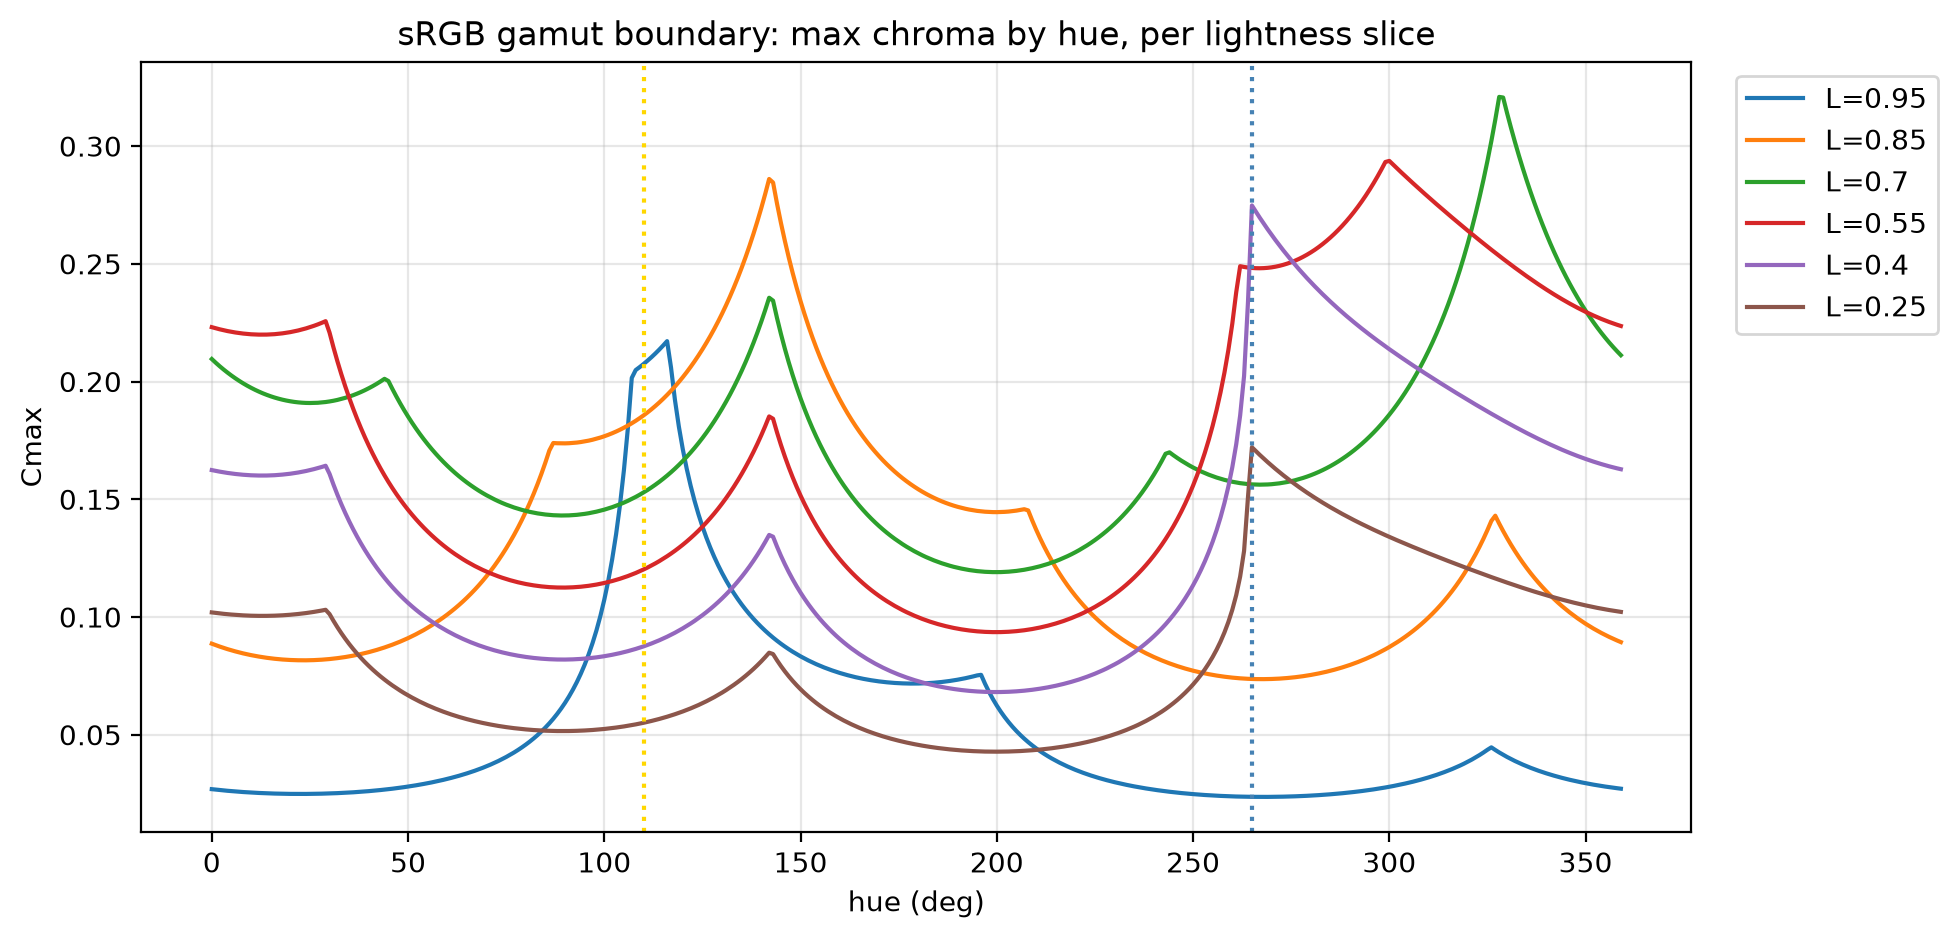

In [ ]:
hs = np.arange(360)
fig, ax = plt.subplots(figsize=(10, 5))
for L in (.95, .85, .70, .55, .40, .25): ax.plot(hs, cmax(L, hs), label=f'L={L}')
for h, c in [(110, 'gold'), (265, 'steelblue')]: ax.axvline(h, ls=':', lw=1.5, color=c)
ax.set(xlabel='hue (deg)', ylabel='Cmax', title='sRGB gamut boundary: max chroma by hue, per lightness slice')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1)); ax.grid(True, alpha=.3); plt.show()

The curve is lumpy, with cusps near the sRGB primaries and secondaries, and its shape changes with lightness. As pointed out by the dotted vertical lines, yellow holds huge chroma when light and little when dark, blue the reverse.

In [ ]:
for L in (.85, .55, .25):
    print(f'L={L}')
    display(swatches([oklch2hex(L, c, h) for c,h in zip(cmax(L, hs12), hs12)], [f'{h}°' for h in hs12]))

L=0.85
L=0.55
L=0.25


<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#ffb6cb;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#ffbaae;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#ffbe8a;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#fac700;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#bedf00;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#00f674;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#00eed2;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#37e6ff;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#9cd6ff;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#bbccff;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#d6c1ff;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#ffadf7;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#cd006c;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#d40f00;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#a75c00;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#8b6e00;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#687c00;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#00893d;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#008474;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#008090;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#0079b3;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#4056ff;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#9200fe;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#ba00b4;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#440020;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#470100;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#361900;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#2b2000;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#1e2500;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#002a0e;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#002922;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#00272d;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#00243a;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#0f006e;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#2e0056;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#3d003b;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

### Vivid chroma

The boundary swatches show that maximum chroma is a limit and not necessarily an aesthetic target. At medium lightness, all colours look good, but at high lightnesses (used for background washes), some colours are garish, while at low lightnesses, blue stands out more than any other colour. 

Capping every hue at the worst hue's maximum would fix the garishness but make the whole palette inherit the narrowest gamut, resulting in muddy colours at medium lightness. Instead, we can aim to impose a chroma ceiling at low and high lightnesses, relaxing in the middle.

A simple candidate ceiling is a quadratic in lightness: zero at the poles, where boundary colours were worst, peaking at mid-lightness.

In [ ]:
def ctarget(L, peak=.2):
    "Chroma ceiling: zero at the poles, `peak` at L=.5"
    return peak * 4*L*(1-L)

def palette_c(L, h, peak=.2):
    return np.minimum(ctarget(L, peak), cmax(L, h))

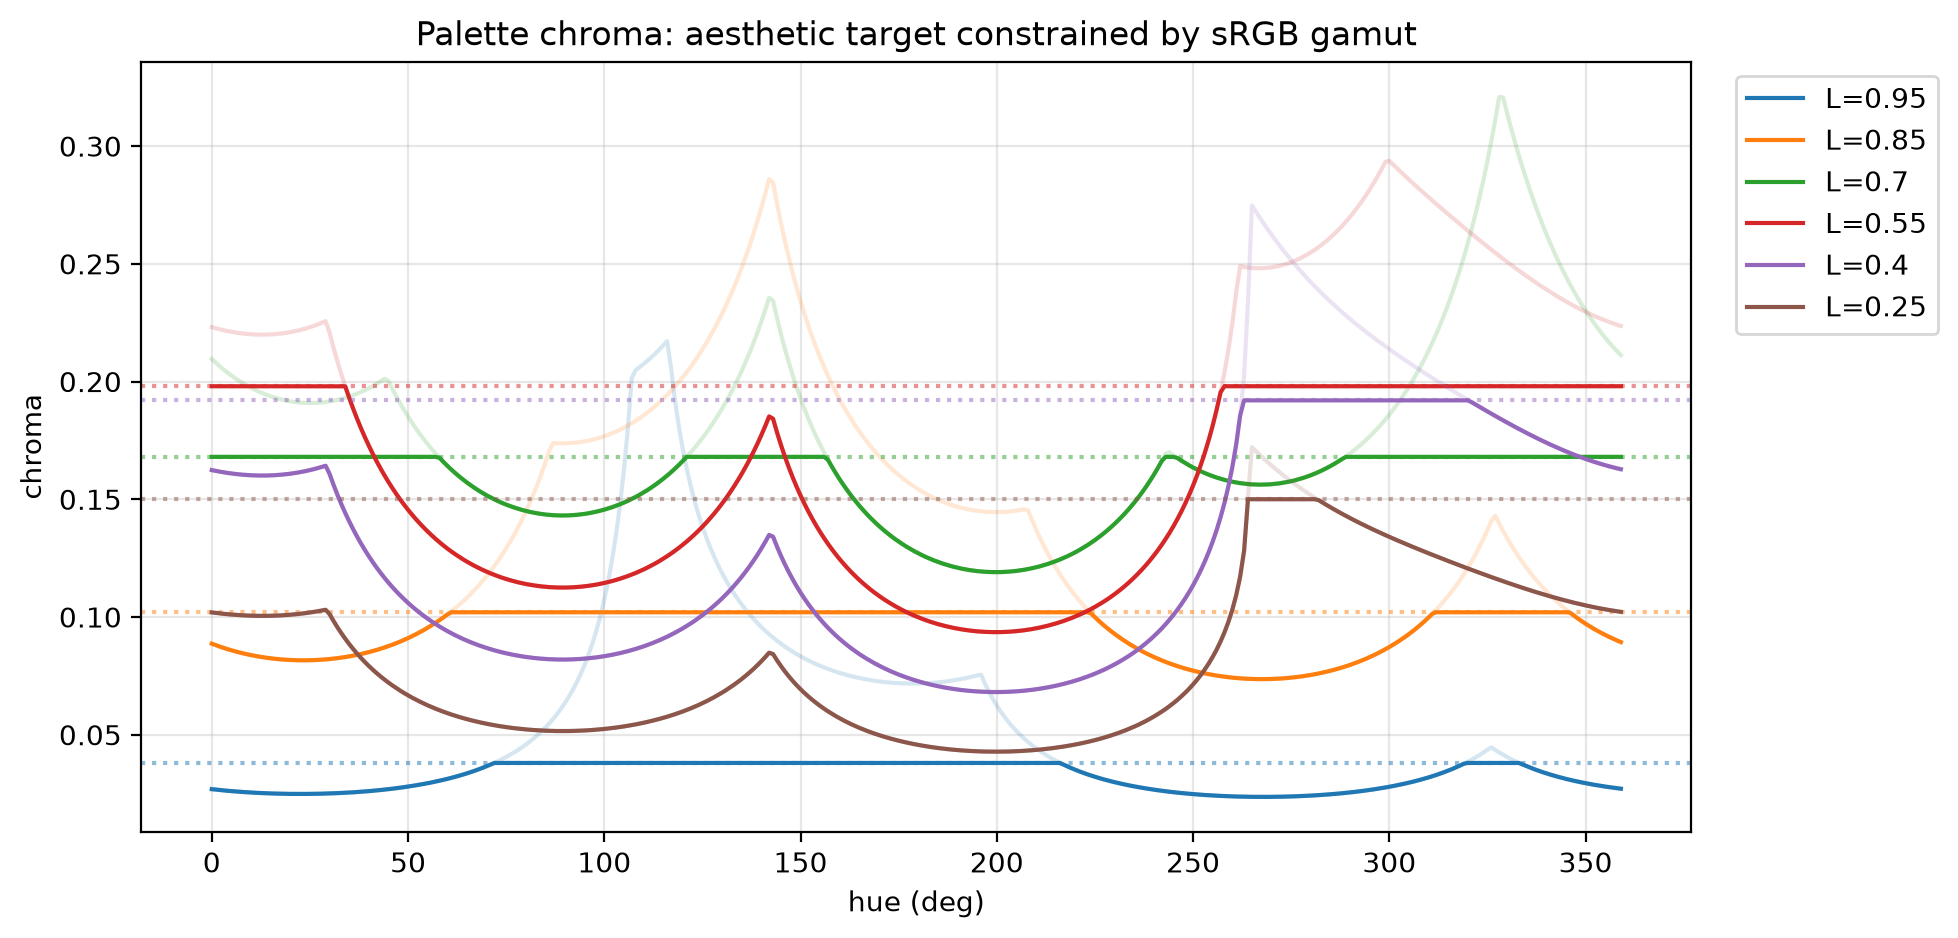

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

for L in (.95, .85, .70, .55, .40, .25):
    line, = ax.plot(hs, palette_c(L, hs), label=f'L={L}')
    clr = line.get_color()
    ax.plot(hs, cmax(L, hs), color=clr, alpha=.18)
    ax.axhline(ctarget(L), color=clr, ls=':', alpha=.5)

ax.set(
    xlabel='hue (deg)', ylabel='chroma',
    title='Palette chroma: aesthetic target constrained by sRGB gamut')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
ax.grid(True, alpha=.3)
plt.show()

In [ ]:
for L in (.95, .85, .70, .55, .40, .25):
    display(swatches(
        [oklch2hex(L, palette_c(L, h), h) for h in hs12],
        [f'{h}°' for h in hs12]))

<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#ffe7ee;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#ffe9e5;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#ffeada;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#f8eed2;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#ebf3d7;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#ddf6e1;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#d4f7ef;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#d2f6fd;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#dff1ff;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#e8eeff;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#f1ebff;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#fee6fb;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#ffb6cb;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#ffbaae;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#ffbe8a;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#e8cb7e;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#c5d88b;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#9de1ab;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#7ce4d0;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#75e0f3;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#9cd6ff;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#bbccff;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#d6c1ff;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#f4b6ee;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#ef6b9a;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#f56f5c;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#e68100;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#c19900;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#92ac00;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#3aba63;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#00b8a1;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#00b2c8;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#00a9f7;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#7997ff;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#af83f6;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#d773cf;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#c5276d;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#cc2b1c;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#a75c00;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#8b6e00;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#687c00;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#00893d;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#008474;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#008090;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#0079b3;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#4761e3;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#864bd1;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#ad37a7;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#850044;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#8a0600;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#6b3900;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#594500;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#414e00;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#005724;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#005449;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#00515c;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#004d74;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#2632ac;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#5b189d;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#780075;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#440020;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#470100;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#361900;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#2b2000;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#1e2500;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#002a0e;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#002922;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#00272d;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#00243a;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#0e0967;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#2e0056;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#3d003b;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

The quadratic tames the light end and largely defers to the gamut when dark, but its lightest rows still look a little saccharine. We add a `shape` exponent to flatten the curve into the poles, draining tint from the extremes while leaving the middle alone.

In [ ]:
def ctarget(L, peak=.2, shape=1.):
    "Chroma ceiling: zero at the poles, `peak` at L=.5"
    return peak * (4*L*(1-L))**shape

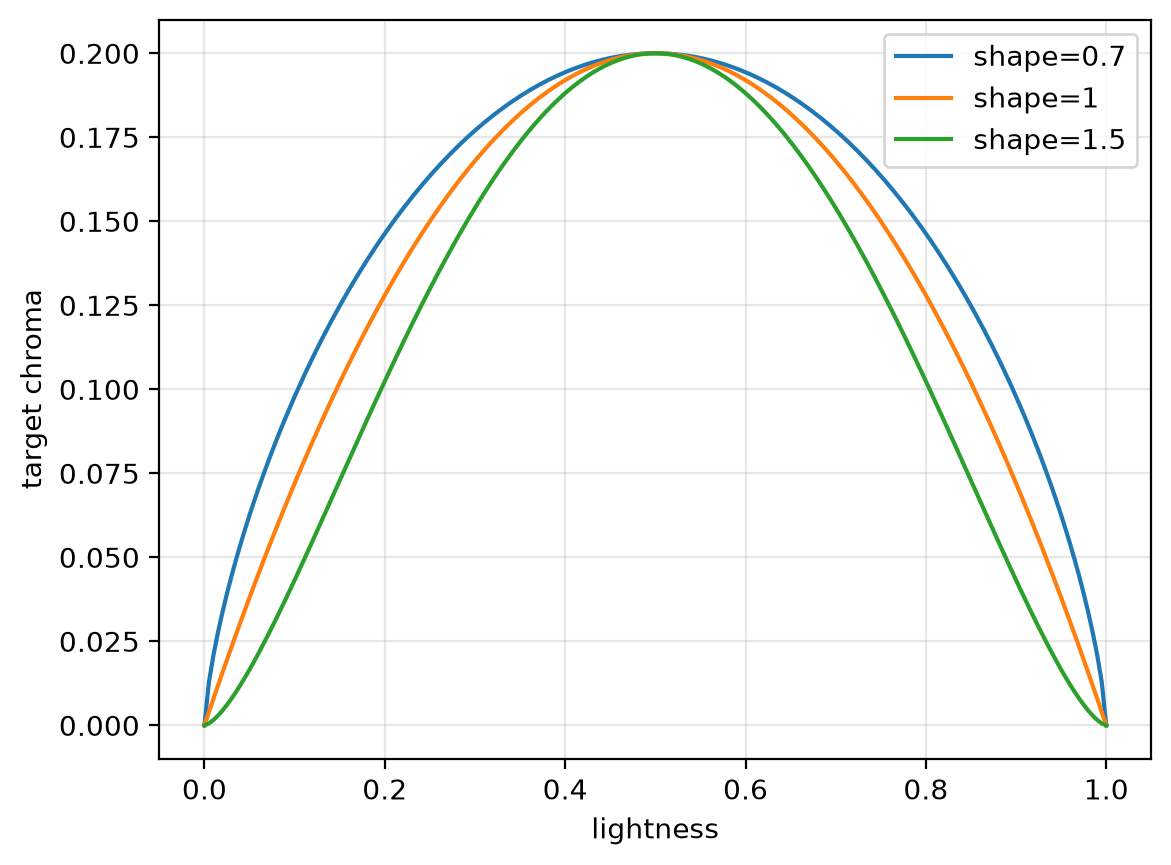

In [ ]:
Ls = np.linspace(0, 1, 200)
for shape in (.7, 1, 1.5):
    plt.plot(Ls, ctarget(Ls, shape=shape), label=f'{shape=}')
plt.xlabel('lightness'); plt.ylabel('target chroma')
plt.legend(); plt.grid(alpha=.3)

In [ ]:
def palette_c(L, h, peak=.2, shape=1.5):
    return np.minimum(ctarget(L, peak, shape), cmax(L, h))

In [ ]:
for L in (.95, .85, .70, .55, .40, .25):
    display(swatches(
        [oklch2hex(L, palette_c(L, h), h) for h in hs12],
        [f'{h}°' for h in hs12]))

<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#f9eaee;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#f9ebe8;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#f7ece4;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#f3eee2;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#edf0e4;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#e7f2e9;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#e3f2ef;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#e3f2f5;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#e5f0f9;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#eaeefa;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#f0ecf8;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#f5ebf4;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#f7bacc;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#fabdb2;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#f2c39e;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#e0cc97;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#c7d5a0;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#acdcb5;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#98decf;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#94dbe8;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#a3d5f9;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#bbccfe;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#d5c4f7;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#eabde5;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#e9719a;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#ef7563;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#e28421;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#c19900;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#93ab25;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#48b869;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#00b8a1;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#00b2c8;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#1ca9f3;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#7a97fe;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#ae86ef;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#d378cb;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#c4286d;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#cb2c1d;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#a75c00;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#8b6e00;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#687c00;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#00893d;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#008474;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#008090;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#0079b3;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#4862e2;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#864bd1;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#ad38a7;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#850044;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#8a0600;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#6b3900;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#594500;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#414e00;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#005724;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#005449;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#00515c;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#004d74;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#2633aa;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#5a1b9b;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#780075;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#440020;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#470100;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#361900;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#2b2000;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#1e2500;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#002a0e;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#002922;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#00272d;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#00243a;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#0e125e;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#2d0255;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#3d003b;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

`shape=1.5` mostly affects the pale and dark rows — the `.95` row now reads as gently tinted surfaces rather than pastel accents — while the solid region is untouched. We adopt `peak=.2, shape=1.5` for now.

### Neutral chroma

For the vivid ladder, we want strong colour without becoming garish. The neutral ladder has a different goal: it should remain recognisably neutral while carrying just enough of the context hue to tint its surfaces and text.

Oklab represents a colour as three axes: $L$ (perceived lightness), $a$ (green↔red), and $b$ (blue↔yellow). The polar form — oklch — replaces $a, b$ with chroma $C$ and hue $h$, but both forms describe the same colour. Oklab defines a perceptual colour-difference metric, $\Delta E_{\mathrm{OK}}$, which measures how different two colours *look* as a single number:

$$\Delta E_{\mathrm{OK}} = \sqrt{\Delta L^2 + \Delta a^2 + \Delta b^2}$$

When comparing an achromatic colour $(L, 0, h)$ against a chromatic one at the same lightness and hue, $\Delta L = 0$ and the $a/b$ difference reduces to $C$, so this simplifies to:

$$\Delta E_{\mathrm{OK}} = C$$

That is: chroma *is* the perceptual distance from grey, in Oklab units. CSS Color 4 (§14.2.1) defines one *just-noticeable difference* (JND) as $\Delta E_{\mathrm{OK}} = 0.02$, so a neutral colour with $C = 0.02$ is just barely distinguishable from pure grey. See [Binary Search Gamut Mapping](https://www.w3.org/TR/css-color-4/#binsearch-gamut-mapping).

In [ ]:
JND = .02
L = .7
swatches([oklch2hex(L, np.minimum(JND, cmax(L, h)), h) for h in hs12], [f'{h}°' for h in hs12])

<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#aa9a9e;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#ab9a97;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#a89c92;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#a39e91;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#9da093;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#96a298;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#92a39f;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#91a2a5;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#94a0aa;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#999eab;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#a09ca9;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#a69aa4;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

## Ladder Design

Our colour palette will be structured as ladders of prominence steps. Here we decide what steps each ladder requires and pair them with their targets. Later, we will use the targets to constrain an optimiser that finds what lightness each step should be set to.

### Parameters

We initialise a `params` dict that will hold any tunable aesthetic parameters

In [ ]:
params = dict(
    vivid_peak=.2, vivid_shape=1.5,  # aesthetic chroma ceiling
    neutral_tint=1,                  # neutral tint, in JNDs from grey
)

def vivid_ceil(L): return ctarget(L, params['vivid_peak'], params['vivid_shape'])
def neutral_ceil(L): return params['neutral_tint']*JND
def capped(ceil, L, h): return np.minimum(ceil(L), cmax(L, h))

### Base/page colour

The base is the least-prominent rung and the default page colour. App backgrounds conventionally sit very close to but not exactly at white or black: we choose `pole_contrast = 1.1` so that our page background is near enough to read as the pole but far enough inside it to carry hue.

In [ ]:
params['pole_contrast'] = 1.1

For achromatic (zero chroma, i.e. pure grey) OKLCH, relative luminance is \(Y=L^3\). Solving the WCAG contrast formula against white (\(Y=1\)) and black (\(Y=0\)) gives:

In [ ]:
base = dict(
    light=np.cbrt(1.05/params['pole_contrast'] - .05),
    dark=np.cbrt(.05*(params['pole_contrast'] - 1)))
base

{'light': np.float64(0.9671120588933684),
 'dark': np.float64(0.17099759466766976)}

As our neutral ladder will carry one JND of context tint, the luminance will change slightly per hue and therefore the constrast too. We can find the hue with the lowest contrast to the relevant pole.

In [ ]:
hgrid = np.arange(360)

def worst_pole_contrast(L, mode):
    "Lowest neutral-base contrast against its achromatic pole, and its hue"
    pole = 1 if mode == 'light' else 0
    ys = oklch2lum(L, capped(neutral_ceil, L, hgrid), hgrid)
    cs = contrast(ys, pole)
    i = np.argmin(cs)
    return cs[i], hgrid[i]

In [ ]:
for mode, L in base.items():
    c, h = worst_pole_contrast(L, mode)
    print(f'{mode:5}  L={L:.4f}  worst={c:.3f}:1  (hue {h}°)')

light  L=0.9671  worst=1.092:1  (hue 174°)
dark   L=0.1710  worst=1.096:1  (hue 353°)


The lightness level that was solved assuming achromatic colours results in insufficient contrast. We therefore solve numerically for the lightness at which the worst sampled hue reaches `pole_contrast`.

In [ ]:
def solve_L(f, target, a=0, b=1):
    "Lightness where scalar function `f(L)` equals `target`"
    return brentq(lambda L: f(L) - target, *sorted((a, b)))

base = {mode: solve_L(lambda L: worst_pole_contrast(L, mode)[0], params['pole_contrast']) for mode in ('light', 'dark')}
base

{'light': 0.9645603627942881, 'dark': 0.17358123558891084}

The tint moves the light base slightly darker and the dark base slightly lighter.

In [ ]:
for mode, L in base.items():
    c, _ = worst_pole_contrast(L, mode)
    test_close(c, params['pole_contrast'], eps=1e-8)
    assert in_gamut(L, capped(neutral_ceil, L, hgrid), hgrid).all() 
    print(f'{mode:5} JNDs={(abs(L - (1 if mode == 'light' else 0)) / JND):.1f}')

light JNDs=1.8
dark  JNDs=8.7


Note the single `pole_contrast` is asymmetric in perceptual terms: about 2 JNDs from white, but nearer 9 from black. The WCAG contrast formula's +0.05 flare term accounts for ambient light scattering, which swamps small differences near black far more than near white, so an equal contrast ratio produces an equal degree of "page-ness" under real viewing despite the unequal JND counts.

### Ladder jobs

[Radix Colors](https://www.radix-ui.com/colors/docs/palette-composition/understanding-the-scale) documents a twelve-step scale with at least one use case per step: app and subtle backgrounds (1–2), component backgrounds and their hover and selected states (3–5), borders and focus rings (6–8), solid fills (9–10), and text (11–12).

Our rungs will carry the same inventory, split across the two families: the neutral ladder takes the page, surfaces, borders, and ordinary text, and the vivid ladder takes the washes, rings, solids, and accent text, so six signed steps per family cover the twelve.

Where Radix describes each step's use in prose and hand-tunes all twelve swatches per hue, we attach each use to its rung as a *job* with a measurable target.

We use two different units for our targets. Contrast measures legibility, but it is a function of luminance only, which is sometimes insufficient; e.g. a wash and a raised surface should both be e.g. `1.1:1` from the base, but they should also differ in tint, which contrast doesn't account for. So we require `sep=2` JNDs between them (a wash only 1 JND from a card would be barely distinguishable).

In [ ]:
params['sep'] = 2

In [ ]:
def job(desc, c=None, bg='n-3', d=None):
    "A use of a rung: optional contrast target `c` or ΔEOK target `d` (in JNDs), measured against rung `bg` (default: the base)"
    return dict(desc=desc, c=c, bg=bg, d=d)

def ladder(ceil, rungs):
    "A family of rungs sharing the aesthetic ceiling `ceil(L)`: name -> jobs"
    return {nm: dict(jobs=js if isinstance(js, tuple) else (js,), ceil=ceil) for nm, js in rungs.items()}

The neutral ladder runs at near-zero chroma. Its first rung is the base (the lightness extreme and default page), whose lightness was derived from the chosen pole contrast; everything else will be placed relative to it.


In [ ]:
neutral = ladder(neutral_ceil, {
    'n-3': job('base: the lightness extreme (the default page)'),
    'n-2': job('raised surface: cards, inputs', c=params['pole_contrast']),
    'n-1': job('hairline borders, separators'),
    'n':   job('disabled text and controls'),
    'n1':  job('muted and placeholder text', c=4.5, bg='n-2'),
    'n2':  (job('body text', c=7), job('body text on surface', c=7, bg='n-2')),
})

The vivid ladder carries the accent family.

In [ ]:
vivid = ladder(vivid_ceil, {
    'v-3': (job('subtle background wash', c=params['pole_contrast']), job('distinct from raised surface', d=params['sep'], bg='n-2')),
    'v-2': job('wash hover, selected'),
    'v-1': (job('border, focus ring', c=3, bg='n-2'), job('large accent text', c=3)),
    'v':   (job('solid fill with base-coloured label', c=4.5), job('accent text on surface', c=4.5, bg='n-2')),
    'v1':  job('solid hover'),
    'v2':  (job('strong accent text on surface', c=7, bg='n-2'), job('alert text on wash', c=4.5, bg='v-3')),
})
rungs = neutral | vivid

Rungs with targets will get their lightness determined through optimisation such that the targets hold at all hues. Unpinned rungs will be spaced geometrically in contrast between their pinned neighbours.

## Ladder Optimisation

With the bases fixed, we can generalize the same calculation to any pair of ladder rungs.

In [ ]:
def worst_contrast(L1, C1, L2, C2):
    "Lowest contrast between two rungs, each at its own independently-worst context hue"
    y1, y2 = oklch2lum(L1, C1, hgrid), oklch2lum(L2, C2, hgrid)
    return contrast(y1[:,None], y2[None,:]).min()

def worst_sep(L1, C1, L2, C2):
    "Lowest same-hue ΔEOK between two rungs, in JNDs"
    return np.sqrt((L1-L2)**2 + (C1-C2)**2).min()/JND

Before solving the contrast-pinned rungs, we check that contrast changes monotonically as vivid lightness moves away from the base.

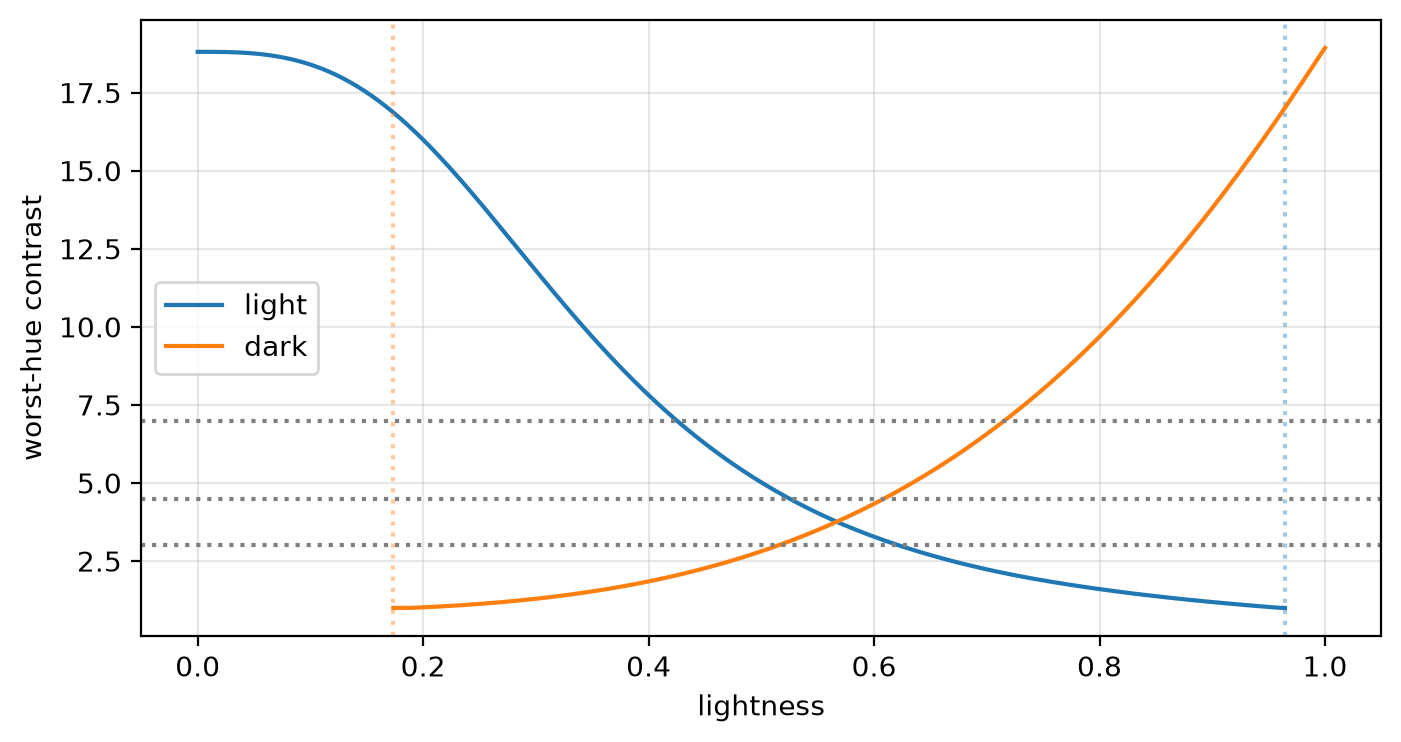

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
for mode, baseL in base.items():
    edge = 0 if mode == 'light' else 1
    Ls = np.linspace(baseL, edge, 300)
    cs = [worst_contrast(L, capped(vivid_ceil, L, hgrid), baseL, capped(neutral_ceil, baseL, hgrid)) for L in Ls]
    ax.plot(Ls, cs, label=mode)
    ax.axvline(baseL, ls=':', color=ax.lines[-1].get_color(), alpha=.4)
for t in (3, 4.5, 7): ax.axhline(t, ls=':', color='gray')
ax.set(xlabel='lightness', ylabel='worst-hue contrast')
ax.legend(); ax.grid(alpha=.3)

The two curves are smooth and monotonic over their relevant intervals. Each contrast target has one crossing, so its rung lightness can be found with the same scalar root solver used for the base. The shapes of the curves are different, showing that the dark ladder cannot simply invert the light ladder: their contrast-pinned lightnesses must be derived separately.

### Rungs with targets

To place a rung, we search outward from its background for the first lightness at which every one of its jobs passes; e.g. a `c=4.5` job passes when the worst-hue contrast against its background reaches 4.5.

A candidate rung is measured through its `(L, C)` pair: the lightness being tried, and the family ceiling capped by the gamut at that lightness.

In [ ]:
def py_chroma(nm, L, h=hgrid):
    "Derived chroma of rung `nm` at lightness `L`: its family ceiling capped by the gamut"
    return capped(rungs[nm]['ceil'], L, h)

def LC(nm, L, chroma=py_chroma):
    "Rung `nm` at lightness `L`, as the (L, C) pair the worst-case measures take"
    return L, chroma(nm, L)

We'll pad targets by a small `margin` to account for 8-bit rounding.

In [ ]:
params['margin'] = 1.01

Let's first place two rungs by hand in light mode, starting from the base we derived earlier. First, `n-2`:

In [ ]:
lv = {'n-3': base['light']}
lv['n-2'] = solve_L(lambda L: worst_contrast(*LC('n-2', L), *LC('n-3', lv['n-3'])), target=params['pole_contrast']*params['margin'], a=lv['n-3'], b=0)
{nm: round(L, 4) for nm, L in lv.items()}

{'n-3': 0.9646, 'n-2': 0.9243}

In [ ]:
test_close(worst_contrast(*LC('n-2', lv['n-2']), *LC('n-3', lv['n-3'])), params['pole_contrast']*params['margin'], eps=1e-6)

A rung can carry several jobs, in two different units. Dividing each measurement by its target puts them on one scale — a job passes at 1 — and a rung passes where its worst ratio does. So multi-job placement is single-root-finding again: solve the min ratio to margin, starting from the most prominent background. The wash `v-3` carries one job of each unit:

In [ ]:
def score(L): return min(
    worst_contrast(*LC('v-3', L), *LC('n-3', lv['n-3'])) / params['pole_contrast'],
    worst_sep(*LC('v-3', L), *LC('n-2', lv['n-2'])) / params['sep'])

lv['v-3'] = solve_L(score, params['margin'], min(lv['n-3'], lv['n-2']), 0)
{nm: round(L, 4) for nm, L in lv.items()}

{'n-3': 0.9646, 'n-2': 0.9243, 'v-3': 0.894}

Let's generalise to work for any rung. Our solver takes a chroma function as a parameter, so we can later re-run the same optimisation against the chroma the browser actually computes from CSS `oklch()`.

In [ ]:
def job_ratio(j, lc, bg):
    "Worst-case measurement of job `j` over its target: 1 is a pass"
    if j['c']: return worst_contrast(*lc, *bg) / j['c']
    return worst_sep(*lc, *bg) / j['d']

def solve_jobs(mode, nm, levels, chroma=py_chroma):
    "Closest outward lightness for `nm` satisfying every targeted job, measured with `chroma`"
    jobs = [j for j in rungs[nm]['jobs'] if j['c'] or j['d']]
    bgs = {j['bg']: LC(j['bg'], levels[j['bg']], chroma) for j in jobs}
    start = (min if mode == 'light' else max)(L for L, _ in bgs.values())
    return solve_L(lambda L: min(job_ratio(j, LC(nm, L, chroma), bgs[j['bg']]) for j in jobs),
                   params['margin'], start, 0 if mode == 'light' else 1)

In [ ]:
for nm in ('n-2', 'v-3'): test_close(solve_jobs('light', nm, lv), lv[nm])

### Rungs without targets

Rungs without targets are spaced evenly (geometrically, as contrast is a ratio) between their placed neighbours, measured as contrast against the base.

Place `n1` with the solver and fill in the gaps by hand:

In [ ]:
lv['n1'] = solve_jobs('light', 'n1', lv)
def cbase(nm, L): return worst_contrast(*LC(nm, L), *LC('n-3', lv['n-3']))

for nm, t in zip(('n-1', 'n'), np.geomspace(cbase('n-2', lv['n-2']), cbase('n1', lv['n1']), 4)[1:-1]):
    lv[nm] = solve_L(lambda L: cbase(nm, L), t, lv['n-3'], 0)
{nm: round(L, 4) for nm, L in lv.items()}

{'n-3': 0.9646,
 'n-2': 0.9243,
 'v-3': 0.894,
 'n1': 0.5083,
 'n-1': 0.7684,
 'n': 0.6318}

Each step should multiply the base contrast by the same factor

In [ ]:
cs = np.array([cbase(nm, lv[nm]) for nm in ('n-2', 'n-1', 'n', 'n1')])
test_close(cs[1:]/cs[:-1], cs[1]/cs[0])

Again, generalise:

In [ ]:
def interp_unpinned(ladder, mode, levels, chroma=py_chroma):
    "Fill each run of unpinned rungs with log-spaced base contrasts between its placed neighbours"
    def cb(nm, L): return worst_contrast(*LC(nm, L, chroma), *LC('n-3', levels['n-3'], chroma))
    nms, edge = list(ladder), 0 if mode == 'light' else 1
    pins = [i for i, nm in enumerate(nms) if nm in levels]
    for a, b in zip(pins, pins[1:]):
        ts = np.geomspace(cb(nms[a], levels[nms[a]]), cb(nms[b], levels[nms[b]]), b-a+1)
        for nm, t in zip(nms[a+1:b], ts[1:-1]): levels[nm] = solve_L(lambda L: cb(nm, L), t, levels['n-3'], edge)

All targets are wrt lower rungs, so placing pinned rungs in declaration order resolves every background before it is needed and interpolation fills the rest.

In [ ]:
def fit_ladders(mode, chroma=py_chroma):
    "Place both ladders: the base, pinned rungs in declaration order, then interpolation"
    levels = {'n-3': solve_L(lambda L: worst_pole_contrast(L, mode)[0], params['pole_contrast'])}
    for nm, r in rungs.items():
        if any(j['c'] or j['d'] for j in r['jobs']): levels[nm] = solve_jobs(mode, nm, levels, chroma)
    for lad in (neutral, vivid): interp_unpinned(lad, mode, levels, chroma)
    return {nm: levels[nm] for nm in rungs}

In [ ]:
levels = {mode: fit_ladders(mode) for mode in ('light', 'dark')}
test_close([levels['light'][nm] for nm in lv], list(lv.values()))
pd.DataFrame(levels).round(4).T

,n-3,n-2,n-1,n,n1,n2,v-3,v-2,v-1,v,v1,v2
light,0.9646,0.9243,0.7684,0.6318,0.5083,0.4053,0.8940,0.7268,0.5896,0.4950,0.4452,0.3952
dark,0.1736,0.2291,0.3770,0.4965,0.6185,0.7340,0.2611,0.4180,0.5444,0.6393,0.6928,0.7484


We check the results to confirm every job holds at its worst hue, each ladder stays in lightness order, and every generated colour stays inside the gamut.

Note, a rung solved to exactly its target can fall below it once its colour is rounded to the 8-bit sRGB that a screen shows (the reason we used `margin` to solve slightly above target), so we measure each job twice: on the exact colours, and on the rounded ones.

In [ ]:
def lum8(L, C):
    "Relative luminance after rounding to 8-bit sRGB"
    return srgb2lum(np.round(np.clip(lin2srgb(oklch2lin(L, C, hgrid)), 0, 1)*255)/255)

def worst_contrast8(L1, C1, L2, C2):
    "`worst_contrast` on the rounded colours"
    return contrast(lum8(L1, C1)[:,None], lum8(L2, C2)[None,:]).min()

In [ ]:
lc, bg = LC('n1', levels['light']['n1']), LC('n-2', levels['light']['n-2'])
worst_contrast(*lc, *bg), worst_contrast8(*lc, *bg)

(np.float64(4.544999999999932), np.float64(4.5026166216372605))

Rounding costs a few thousandths, inside the 1% that `margin` provided. Repeat for all declared jobs:

In [ ]:
def rung_c(nm, mode): return py_chroma(nm, levels[mode][nm])

def failing_jobs(chroma=rung_c, tol=0):
    "Jobs that miss their target under `chroma`, with the measured worst"
    bad = []
    for m in levels:
        for nm, r in rungs.items():
            for j in r['jobs']:
                if not (j['c'] or j['d']): continue
                lc, bg = (levels[m][nm], chroma(nm, m)), (levels[m][j['bg']], chroma(j['bg'], m))
                w = job_ratio(j, lc, bg)
                if j['c']: w = min(w, worst_contrast8(*lc, *bg)/j['c'])
                if w < 1 - tol: bad.append(dict(mode=m, rung=nm, job=j['desc'], ratio=round(w, 3)))
    return bad

In [ ]:
assert not failing_jobs(tol=1e-6)
for m, lvl in levels.items():
    sgn = -1 if m == 'light' else 1
    for lad in (neutral, vivid):
        nms = [lvl[nm] for nm in lad]
        assert (sgn*np.diff(nms) > 0).all()
        assert all(worst_sep(*LC(a, lvl[a]), *LC(b, lvl[b])) >= 1 for a, b in zip(lad, list(lad)[1:]))
    assert all(in_gamut(L, py_chroma(nm, L), hgrid).all() for nm, L in lvl.items())

Visually inspect the palette at a few context hues in light and dark mode

In [ ]:
def rung_hex(nm, mode, h, chroma=rung_c):
    "Displayable hex of rung `nm` at context hue `h`, under chroma function `chroma`"
    return oklch2hex(levels[mode][nm], chroma(nm, mode)[h], h)

def card(*content, mode, h, lbl='', chroma=rung_c):
    "`content` (default: both ladders) on the mode's page at hue `h`, inked in its body text"
    if not content: content = [swatches([rung_hex(nm,mode,h,chroma) for nm in lad], list(lad)) for lad in (neutral, vivid)]
    return Div(Div(lbl, style='font-size:.75rem'), *content,
               style=f'background:{rung_hex("n-3",mode,h,chroma)};color:{rung_hex("n2",mode,h,chroma)};padding:1rem;border-radius:8px;display:flex;flex-direction:column;gap:6px')

In [ ]:
hues = dict(red=25, yellow=100, green=145, blue=260, magenta=330)

def ladder_cards(chroma=rung_c):
    "Light and dark cards for each named hue"
    return Div(*[card(mode=m, h=h, lbl=f'{nm} {h}°, {m}', chroma=chroma) for nm, h in hues.items() for m in ('light', 'dark')],
               style='display:grid;grid-template-columns:1fr 1fr;gap:8px')

ladder_cards()

<div style="display:grid;grid-template-columns:1fr 1fr;gap:8px"><div style="background:#ffefed;color:#544544;padding:1rem;border-radius:8px;display:flex;flex-direction:column;gap:6px"><div style="font-size:.75rem">red 25°, light</div><div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#ffefed;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n-3</div></div><div style="flex:1"><div style="background:#f3e1df;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n-2</div></div><div style="flex:1"><div style="background:#c0afad;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n-1</div></div><div style="flex:1"><div style="background:#968584;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n</div></div><div style="flex:1"><div style="background:#716160;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n1</div></div><div style="flex:1"><div style="background:#544544;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n2</div></div></div><div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#fad1cd;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v-3</div></div><div style="flex:1"><div style="background:#f38079;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v-2</div></div><div style="flex:1"><div style="background:#d73e3e;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v-1</div></div><div style="flex:1"><div style="background:#b9021d;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v</div></div><div style="flex:1"><div style="background:#a00017;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v1</div></div><div style="flex:1"><div style="background:#880012;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v2</div></div></div></div><div style="background:#180d0c;color:#b5a4a3;padding:1rem;border-radius:8px;display:flex;flex-direction:column;gap:6px"><div style="font-size:.75rem">red 25°, dark</div><div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#180d0c;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n-3</div></div><div style="flex:1"><div style="background:#251918;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n-2</div></div><div style="flex:1"><div style="background:#4c3e3c;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n-1</div></div><div style="flex:1"><div style="background:#6d5e5c;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n</div></div><div style="flex:1"><div style="background:#928180;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n1</div></div><div style="flex:1"><div style="background:#b5a4a3;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n2</div></div></div><div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#4c0006;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v-3</div></div><div style="flex:1"><div style="background:#930014;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v-2</div></div><div style="flex:1"><div style="background:#ca262e;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v-1</div></div><div style="flex:1"><div style="background:#e35652;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v</div></div><div style="flex:1"><div style="background:#ee7069;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:c

What remains is getting the browser to compute all of this from `--hue` alone.

## CSS Generation

In the CSS stylesheet that ships, we will have one custom property per rung: a `light-dark()` pair computed by the browser from the context's `--hue` at runtime. Lightness is a per-rung constant that we have just solved and the hue passes straight through. The only hue-dependent part is chroma, the minimum of the rung's ceiling and the gamut boundary at its lightness. CSS cannot compute the gamut boundary, `rung_c`, so we approximate with something it can and verify every job against what actually ships.

### Boundary approximation

A rung whose ceiling clears the boundary at every hue can ship the ceiling as a constant. Only the rungs whose ceiling crosses the boundary need a stand-in. Let's compute the fraction of hues where the boundary, not the ceiling, constrains the rung's chroma:

In [ ]:
def ceiling(nm, mode): return rungs[nm]['ceil'](levels[mode][nm])

boundary_frac = pd.Series({(m, nm): (cmax(L, hgrid) < ceiling(nm, m)).mean()
                   for m in levels for nm, L in levels[m].items()}).sort_values(ascending=False)
gamut_constrained = list(boundary_frac[boundary_frac > 0].index)
boundary_frac.round(2)

dark   v-3    0.88
light  v2     0.83
dark   v-2    0.81
light  v1     0.79
       v      0.70
dark   v-1    0.62
light  v-1    0.59
dark   v      0.51
       v1     0.37
light  n-3    0.35
       v-2    0.19
dark   v2     0.13
light  n-2    0.00
dark   n-2    0.00
       n-1    0.00
       n      0.00
       n1     0.00
       n2     0.00
light  v-3    0.00
       n2     0.00
       n1     0.00
       n      0.00
       n-1    0.00
dark   n-3    0.00
dtype: float64

The capped gamut boundary is periodic in hue and CSS can compute trigonometric functions, so we can use a truncated Fourier series in `--hue` to approximate it.

The fit must never exceed the boundary (G2): ordinary least squares treats overshoot like undershoot, so we re-fit with overshooting hues up-weighted until the series sits below the target everywhere, then take any residue off the constant term.

In [ ]:
def harmonics(h, K):
    "Fourier design matrix over hues `h` in degrees: 1, cos kh, sin kh for k=1..K"
    hr = np.deg2rad(h)[:,None]*np.arange(1, K+1)
    return np.concatenate([np.ones((len(h),1)), np.cos(hr), np.sin(hr)], axis=1)

def fit_below(g, K, iters=40):
    "One-sided K-harmonic fit: approach `g` from below"
    X, w = harmonics(hgrid, K), np.ones_like(g)
    for _ in range(iters):
        sw = np.sqrt(w)[:,None]
        co = np.linalg.lstsq(X*sw, g*sw[:,0], rcond=None)[0]
        over = X@co > g
        if not over.any(): break
        w[over] *= 2
    co[0] -= max(0, (X@co - g).max())
    return co

def fit_rung(nm, mode, K):
    "Coefficients approximating rung `nm`'s derived chroma from below"
    return fit_below(rung_c(nm, mode), K)

The dark wash (`v-3`) is the most gamut-ruled rung. The fit at various values of `K`:

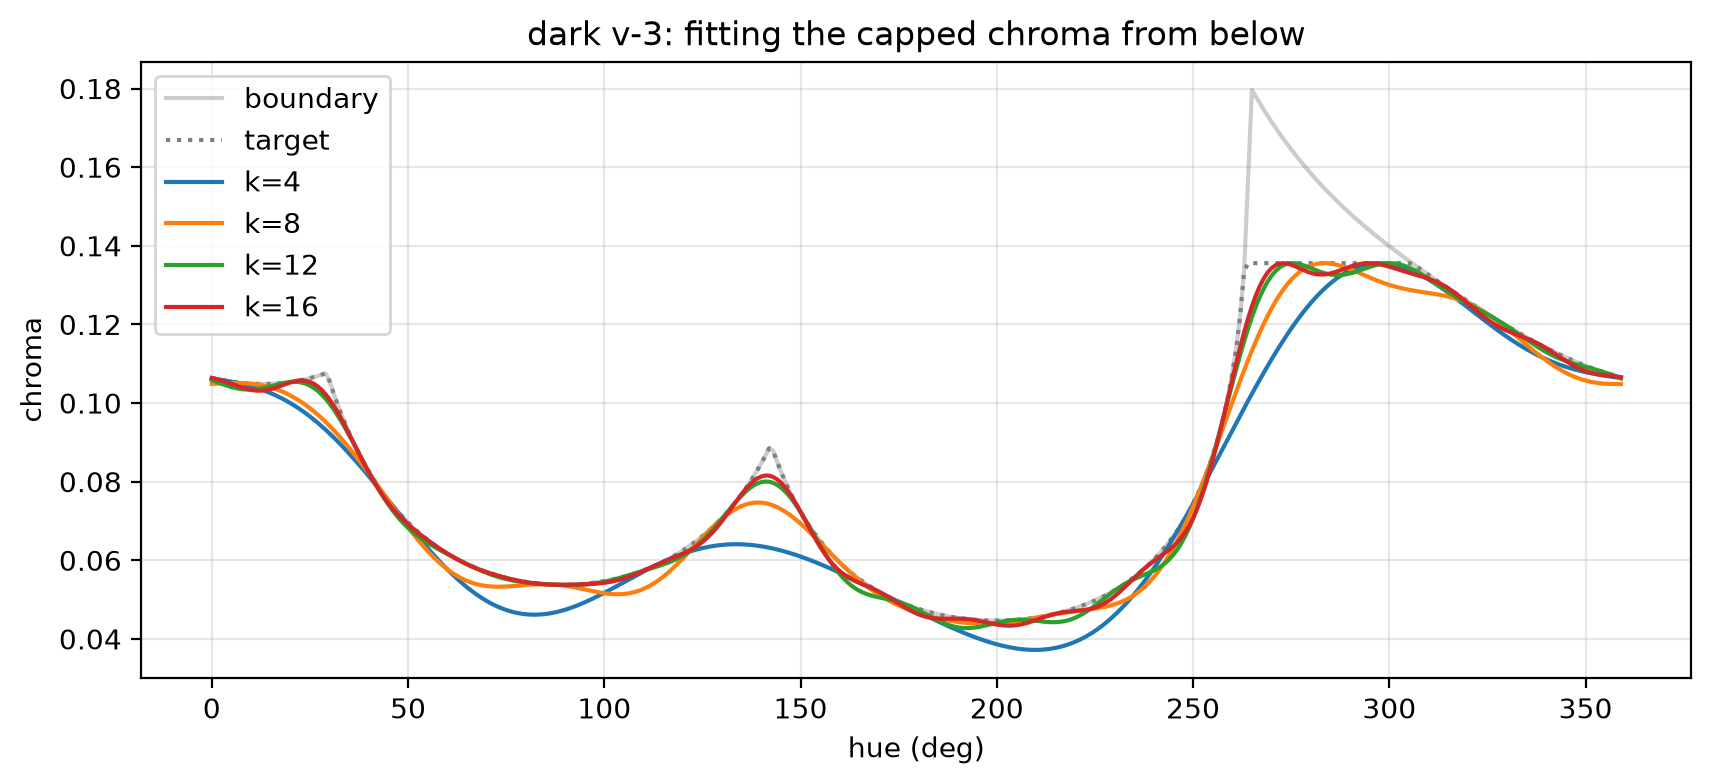

In [ ]:
def plot_fourier_fit(m, nm, ks=(4, 8, 12, 16)):
    "Plot gamut boundary, target chroma, and Fourier fits at harmonic counts `ks` for rung `nm` in mode `m`"
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(hgrid, cmax(levels[m][nm], hgrid), color='gray', alpha=.4, label='boundary')
    ax.plot(hgrid, rung_c(nm, m), ls=':', color='gray', label='target')
    for k in ks: ax.plot(hgrid, harmonics(hgrid, k)@fit_rung(nm, m, k), label=f'{k=}')
    ax.set(xlabel='hue (deg)', ylabel='chroma', title=f'{m} {nm}: fitting the capped chroma from below')
    ax.legend(); ax.grid(alpha=.3)

plot_fourier_fit('dark', 'v-3')

Dark's `v2` is the least gamut-constrained

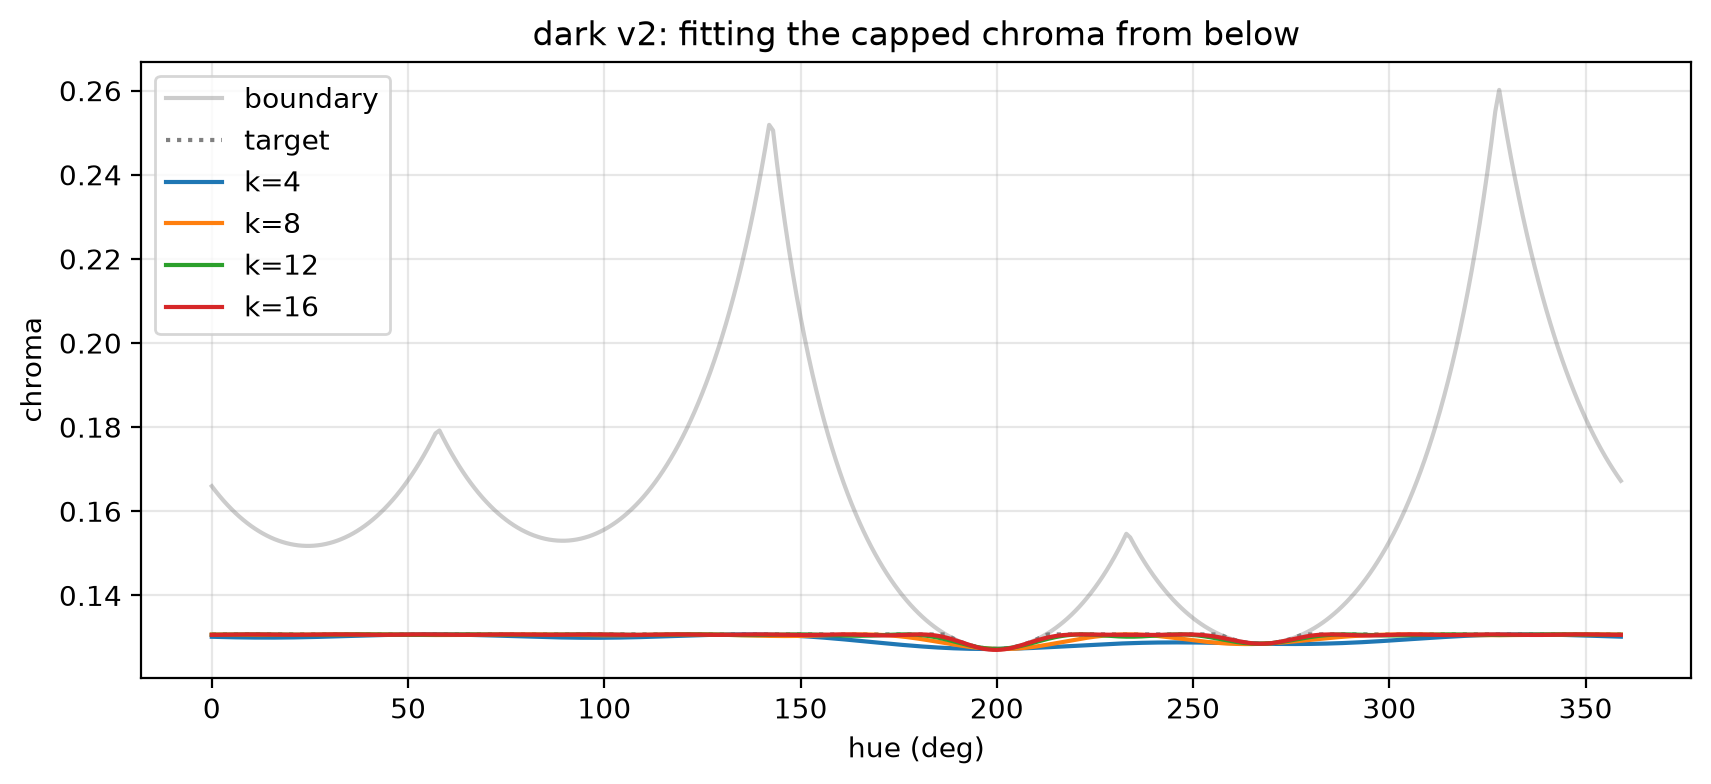

In [ ]:
plot_fourier_fit('dark', 'v2')

Clearly a large `K` is required for some rungs but overkill for others

We measure *retention*: the fitted chroma as a fraction of the derived chroma, at the worst hue.

In [ ]:
def fit_c(nm, mode, K):
    "Chroma the fit delivers for rung `nm`"
    return np.clip(harmonics(hgrid, K)@fit_rung(nm, mode, K), 0, ceiling(nm, mode))

def retention(nm, mode, K):
    "Fitted chroma as a fraction of derived, at the worst hue"
    return (fit_c(nm, mode, K)/rung_c(nm, mode)).min()

pd.DataFrame({K: [retention(nm, m, K) for m, nm in gamut_constrained] for K in (2, 4, 8, 12, 16)},
             index=pd.MultiIndex.from_tuples(gamut_constrained, names=['mode', 'rung'])).round(2)

2     4     8     12    16
mode  rung                              
dark  v-3   0.62  0.71  0.81  0.87  0.88
light v2    0.63  0.72  0.84  0.89  0.91
dark  v-2   0.63  0.72  0.84  0.89  0.90
light v1    0.62  0.73  0.84  0.90  0.92
      v     0.60  0.73  0.84  0.90  0.92
dark  v-1   0.59  0.74  0.84  0.90  0.92
light v-1   0.60  0.78  0.87  0.92  0.95
dark  v     0.69  0.87  0.92  0.95  0.96
      v1    0.81  0.93  0.95  0.97  0.97
light n-3   0.85  0.93  0.96  0.98  0.98
      v-2   0.89  0.93  0.97  0.98  0.98
dark  v2    0.97  0.98  0.98  0.99  0.99

The easy rows are served by a handful of harmonics; past `K=12` the gains are marginal everywhere. A single `K` would overspend on half the rungs or shortchange the rest, so we'll choose `K` per rung

In [ ]:
m, nm = 'light', 'v2'
L, h = levels[m][nm], (fit_c(nm, m, 12)/rung_c(nm, m)).argmin()
ks = (4, 8, 12, 16)
cs = [rung_c(nm, m)[h]] + [fit_c(nm, m, k)[h] for k in ks]
lbls = ['derived'] + [f'K={k} ({fit_c(nm,m,k)[h]/rung_c(nm,m)[h]:.2f})' for k in ks]
display(card(swatches([oklch2hex(L, c, h) for c in cs], lbls), mode=m, h=h, lbl=f'{m} {nm} {h}°'))

<div style="background:#edf4ff;color:#434954;padding:1rem;border-radius:8px;display:flex;flex-direction:column;gap:6px"><div style="font-size:.75rem">light v2 262°</div><div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#0039a6;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">derived</div></div><div style="flex:1"><div style="background:#184090;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">K=4 (0.76)</div></div><div style="flex:1"><div style="background:#113e97;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">K=8 (0.84)</div></div><div style="flex:1"><div style="background:#0c3d9c;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">K=12 (0.89)</div></div><div style="flex:1"><div style="background:#0a3c9d;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">K=16 (0.91)</div></div></div></div>

`K=4` at 76% retention is visibly muddier, but from `K=8` on, the difference is hard to see by eye. 85% seems like a reasonable threshold

In [ ]:
params['retention'] = .85

def solve_K(nm, mode, Kmax=16):
    "Smallest K retaining `params['retention']` of rung `nm`'s derived chroma"
    return next(K for K in range(1, Kmax+1) if retention(nm, mode, K) >= params['retention'])

Ks = {(m, nm): solve_K(nm, m) for m, nm in gamut_constrained}
fits = {(m, nm): fit_rung(nm, m, K) for (m, nm), K in Ks.items()}
pd.Series(Ks)

dark   v-3    11
light  v2      9
dark   v-2     9
light  v1      9
       v       9
dark   v-1     9
light  v-1     7
dark   v       4
       v1      3
light  n-3     2
       v-2     1
dark   v2      1
dtype: int64

### Assembly

Every rung now has its lightness and a hue-dependent chroma function that CSS can compute. All that remains is packing these numbers into the stylesheet.

We can halve the number of terms in the fitted expression by using amplitude-phase form: `a cos(kh) + b sin(kh)` collapses to `R cos(kh - φ)`. We round what the CSS will carry, drop any term with amplitude below `1e-5`, and take the dropped mass and any rounding overshoot off the constant, keeping the series one-sided.


In [ ]:
def floor5(x):
    "Round down to 5 decimals, keeping one-sided approximations one-sided"
    return float(np.floor(x*1e5)/1e5)

def eval_terms(c0, terms, h):
    "The chroma series `c0 + Σ R cos(kh - φ)` at hues `h`"
    hr = np.deg2rad(np.asarray(h, float))
    return c0 + sum((R*np.cos(k*hr - np.deg2rad(phi)) for k, R, phi in terms), np.zeros_like(hr))

def round_fit(co, g):
    "Amplitude-phase form of `co`, rounded and pruned, kept one-sided under target `g`"
    K = (len(co)-1)//2
    c0, terms = co[0], []
    for k in range(1, K+1):
        R = np.hypot(co[k], co[K+k])
        if R < 1e-5: c0 -= R; continue
        terms.append((k, round(float(R), 5), round(float(np.rad2deg(np.arctan2(co[K+k], co[k]))) % 360, 2)))
    c0 -= max(0, (eval_terms(c0, terms, hgrid) - g).max())
    return floor5(c0), terms

Gather the numbers the CSS will carry


In [ ]:
ship = {}
for m in levels:
    for nm, L in levels[m].items():
        s = dict(L=round(L, 4), T=floor5(ceiling(nm, m)))
        if (m, nm) in fits: s['c0'], s['terms'] = round_fit(fits[(m, nm)], py_chroma(nm, s['L']))
        else: s['c0'], s['terms'] = s['T'], []
        ship[(m, nm)] = s

def css_chroma(nm, mode, h=hgrid):
    "Chroma the emitted CSS computes for rung `nm`: the rounded series, clamped to the rounded ceiling"
    s = ship[(mode, nm)]
    return np.clip(eval_terms(s['c0'], s['terms'], np.atleast_1d(h)), 0, s['T'])

A constant rung ships one number. A gamut-constrained rung ships `clamp(0, series, ceiling)`, reading the hue from `--hue` in every term. The tokens are the assembled `light-dark()` pairs, each annotated with the jobs its rung carries, so the shipped file documents itself.

In [ ]:
def chroma_expr(s):
    "CSS for the chroma: a constant, or the clamped series read from `--hue`"
    if not s['terms']: return f"{s['T']}"
    series = f"{s['c0']}" + ''.join(f" + {R}*cos(({k}*var(--hue) - {phi})*1deg)" for k, R, phi in s['terms'])
    return f"clamp(0, {series}, {s['T']})"

def color_css(nm, mode):
    "The rung's `oklch()` colour, reading `--hue`"
    s = ship[(mode, nm)]
    return f"oklch({s['L']} {chroma_expr(s)} var(--hue))"

def ladder_css():
    "The ladder tokens: every rung a light-dark pair computed from `--hue`, with its jobs as a trailing comment"
    def tok(nm): return f"--{nm}: light-dark({color_css(nm, 'light')}, {color_css(nm, 'dark')});"
    def jobs(nm): return '; '.join(j['desc'] for j in rungs[nm]['jobs'])
    return '\n'.join(f"{tok(nm)} /* {jobs(nm)} */" for nm in rungs)

In [ ]:
print(color_css('n1', 'light'))
print(color_css('v-3', 'dark'))
css = ladder_css()
f'{len(css.splitlines())} tokens, {len(css):,} chars'

oklch(0.5083 0.02 var(--hue))
oklch(0.2611 clamp(0, 0.08118 + 0.03727*cos((1*var(--hue) - 324.0)*1deg) + 0.01857*cos((2*var(--hue) - 261.64)*1deg) + 0.01236*cos((3*var(--hue) - 100.29)*1deg) + 0.00447*cos((4*var(--hue) - 81.53)*1deg) + 0.00295*cos((5*var(--hue) - 330.35)*1deg) + 0.00454*cos((6*var(--hue) - 161.37)*1deg) + 0.00108*cos((7*var(--hue) - 148.64)*1deg) + 0.00158*cos((8*var(--hue) - 3.5)*1deg) + 0.00264*cos((9*var(--hue) - 235.89)*1deg) + 0.00067*cos((10*var(--hue) - 214.57)*1deg) + 0.00118*cos((11*var(--hue) - 75.82)*1deg), 0.13557) var(--hue))


'12 tokens, 4,937 chars'

We can now re-verify every declared job with `py_chroma` replaced by `css_chroma`. The fit sits below the derived chroma that the rung placement used, and rounding the lightnesses can cost a few thousandths more; both fall inside the `margin` every job was solved above its target. If any job now fails, the ladders would need re-optimising against `css_chroma`.

In [ ]:
assert not failing_jobs(css_chroma, tol=3e-3)
assert all(in_gamut(ship[(m,nm)]['L'], css_chroma(nm, m), hgrid).all() for m in levels for nm in levels[m])

The ladder card again, this time from the CSS's numbers. It should be hard to tell from the derivation's card.

In [ ]:
ladder_cards(css_chroma)

<div style="display:grid;grid-template-columns:1fr 1fr;gap:8px"><div style="background:#ffefed;color:#544544;padding:1rem;border-radius:8px;display:flex;flex-direction:column;gap:6px"><div style="font-size:.75rem">red 25°, light</div><div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#ffefed;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n-3</div></div><div style="flex:1"><div style="background:#f3e1df;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n-2</div></div><div style="flex:1"><div style="background:#c0afad;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n-1</div></div><div style="flex:1"><div style="background:#968584;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n</div></div><div style="flex:1"><div style="background:#716160;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n1</div></div><div style="flex:1"><div style="background:#544544;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n2</div></div></div><div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#fad1cd;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v-3</div></div><div style="flex:1"><div style="background:#f38079;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v-2</div></div><div style="flex:1"><div style="background:#d73e3e;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v-1</div></div><div style="flex:1"><div style="background:#b61020;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v</div></div><div style="flex:1"><div style="background:#9e0b1a;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v1</div></div><div style="flex:1"><div style="background:#860815;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v2</div></div></div></div><div style="background:#180d0c;color:#b5a4a3;padding:1rem;border-radius:8px;display:flex;flex-direction:column;gap:6px"><div style="font-size:.75rem">red 25°, dark</div><div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#180d0c;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n-3</div></div><div style="flex:1"><div style="background:#251918;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n-2</div></div><div style="flex:1"><div style="background:#4c3e3c;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n-1</div></div><div style="flex:1"><div style="background:#6d5e5c;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n</div></div><div style="flex:1"><div style="background:#928180;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n1</div></div><div style="flex:1"><div style="background:#b5a4a3;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n2</div></div></div><div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#4a0207;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v-3</div></div><div style="flex:1"><div style="background:#910a17;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v-2</div></div><div style="flex:1"><div style="background:#c9282f;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v-1</div></div><div style="flex:1"><div style="background:#e35652;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v</div></div><div style="flex:1"><div style="background:#ed706a;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:c

## Demo

Let's build a minimal stylesheet using the ladder tokens to colour the page and a few components:

In [ ]:
from answerui.demo import demo
from fasthtml.common import Article, H3, P, Em, A, Hr, Button

In [ ]:
demo_css = 'body, article{' + ladder_css() + '''}
body{--hue:260;color-scheme:light;background:var(--n-3);color:var(--n2);margin:0;padding:1.5rem;font-family:system-ui}
article{background:var(--n-2);border:1px solid var(--n-1);border-radius:6px;padding:1rem;max-width:18rem}
a{color:var(--v)}
hr{border:none;border-top:1px solid var(--n-1)}
button{background:var(--v);color:var(--n-3);border:none;border-radius:6px;padding:.5rem 1rem}
button:hover{background:var(--v1)}
button[secondary]{background:var(--v-3);color:var(--v2);border:1px solid var(--v-1)}
'''

def payment_card(**kw):
    return Article(
        H3('Payment method'),
        P('Your card ending in ', Em('4242'), ' expires soon. ', A('See all cards', href='#'), '.'),
        Hr(),
        Button('Update card'), ' ', Button('Remind me later', secondary=True),
        **kw)

demo(payment_card(), css=demo_css)

A danger context is one added line: a `danger` attribute re-points `--hue`, and the card's surface, border, separator, link, and both buttons re-derive — the page around it stays put. Tokens resolve `--hue` where they are declared, which is why the ladder is declared on `article` as well as `body`.

In [ ]:
demo_css += 'article[danger]{--hue:25}'
demo(payment_card(danger=True), css=demo_css)

Each token is a `light-dark()` pair, so if we change `color-scheme` the whole page re-derives.

In [ ]:
demo(payment_card(), css=demo_css + 'body{color-scheme:dark}')

## Shipping

This notebook exports no module; its product is the stylesheet fragment, written to a CSS file, which `answerui.tokens` registers as the palette chunk. Re-running the notebook after changing a parameter regenerates the file, and every change is reviewable as a CSS diff.

In [ ]:
p = get_config().lib_path/'css'; p.mkdir(exist_ok=True)
(p/'palette.css').write_text(ladder_css())

Path('/Users/jackhogan/Code/aai/answerui/answerui/css/palette.css')